In [3]:
!pip install "paho-mqtt<2" pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for paho-mqtt: filename=paho_mqtt-1.6.1-py3-none-any.whl size=62200 sha256=7aaf1b7d6792fe64db64a89a99153830f91fdb08c952558981a30347e75d8ba5
  Stored in directory: /root/.cache/pip/wheels/f9/58/b1/af83cc69fc3ea9dcfafeb61e26c7fa7bcfca4fdf276791c6dc
Successfully built paho-mqtt


In [6]:
import paho.mqtt.client as mqtt
import json, time
import pandas as pd

BROKER = "broker.hivemq.com"
PORT   = 1883
TOPIC  = "iot-DHT-4827/sensor"      # must match MQTT_TOPIC in Wokwi exactly
DURATION = 60                        # seconds to collect

rows = []

def on_connect(client, userdata, flags, rc):
    print("Connected to broker, rc =", rc)
    client.subscribe(TOPIC)

def on_message(client, userdata, msg):
    try:
        d = json.loads(msg.payload.decode())
        d["time"] = pd.Timestamp.now()
        rows.append(d)
        print(d)
    except Exception as e:
        print("Bad message:", msg.payload, e)

client = mqtt.Client()               # works with paho-mqtt 1.6.1 (what you installed)
client.on_connect = on_connect
client.on_message = on_message
client.connect(BROKER, PORT, 60)

client.loop_start()
time.sleep(DURATION)
client.loop_stop()
client.disconnect()

df = pd.DataFrame(rows)
df.to_csv("sensor_data.csv", index=False)
print(len(df), "readings collected")
df.head()

Connected to broker, rc = 0
0 readings collected


""


In [7]:
import paho.mqtt.client as mqtt, time

TOPIC = "iot-DHT-4827/sensor"

def on_connect(c, u, f, rc):
    print("Connected rc =", rc)
    c.subscribe("iot-DHT-4827/#")

def on_subscribe(c, u, mid, granted):
    print("Subscribed")
    c.publish(TOPIC, '{"temp":99,"hum":99,"alarm":1,"source":"colab-test"}')

def on_message(c, u, m):
    print("GOT:", m.topic, m.payload.decode())

c = mqtt.Client()
c.on_connect = on_connect
c.on_subscribe = on_subscribe
c.on_message = on_message
c.connect("broker.hivemq.com", 1883, 60)
c.loop_start()
time.sleep(40)
c.loop_stop()

Connected rc = 0
Subscribed
GOT: iot-DHT-4827/sensor {"temp":99,"hum":99,"alarm":1,"source":"colab-test"}
GOT: iot-DHT-4827/sensor {"temp":24.0,"hum":40.0,"alarm":0}
GOT: iot-DHT-4827/sensor {"temp":24.0,"hum":40.0,"alarm":0}


In [8]:
import paho.mqtt.client as mqtt
import json, time
import pandas as pd

BROKER = "broker.hivemq.com"
TOPIC  = "iot-DHT-4827/sensor"
DURATION = 120          # seconds; Wokwi is slow, so give it time

rows = []

def on_connect(c, u, f, rc):
    print("Connected rc =", rc)
    c.subscribe(TOPIC)

def on_message(c, u, m):
    try:
        d = json.loads(m.payload.decode())
        if d.get("source") == "colab-test":     # ignore my test message
            return
        d["time"] = pd.Timestamp.now()
        rows.append(d)
        print(d)
    except Exception as e:
        print("Bad message:", m.payload, e)

c = mqtt.Client()
c.on_connect = on_connect
c.on_message = on_message
c.connect(BROKER, 1883, 60)
c.loop_start()
time.sleep(DURATION)
c.loop_stop()
c.disconnect()

df = pd.DataFrame(rows)
df.to_csv("sensor_data.csv", index=False)
print(len(df), "readings collected")
df.head()

Connected rc = 0
0 readings collected


""


In [10]:
import paho.mqtt.client as mqtt
import json, time
import pandas as pd

BROKER = "broker.hivemq.com"
DURATION = 120
rows = []

def on_connect(c, u, f, rc):
    print("Connected rc =", rc)
    c.subscribe("iot-DHT-4827/#")

def on_message(c, u, m):
    print("RAW:", m.topic, m.payload.decode())
    try:
        d = json.loads(m.payload.decode())
        if d.get("source") == "colab-test":
            return
        d["time"] = pd.Timestamp.now()
        rows.append(d)
    except Exception as e:
        print("Bad message:", e)

c = mqtt.Client()
c.on_connect = on_connect
c.on_message = on_message
c.connect(BROKER, 1883, 60)
c.loop_start()
time.sleep(DURATION)
c.loop_stop()
c.disconnect()

df = pd.DataFrame(rows)
df.to_csv("sensor_data.csv", index=False)
print(len(df), "readings collected")
df.head()

Connected rc = 0
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/sensor {"temp":17.1,"hum":32.0,"alarm":0}
RAW: iot-DHT-4827/senso

,temp,hum,alarm,time
0,17.1,32.0,0,2026-10-21 17:55:53.574673
1,17.1,32.0,0,2026-10-21 17:55:57.442370
2,17.1,32.0,0,2026-10-21 17:56:01.421905
3,17.1,32.0,0,2026-10-21 17:56:04.512654
4,17.1,32.0,0,2026-10-21 17:56:07.470879


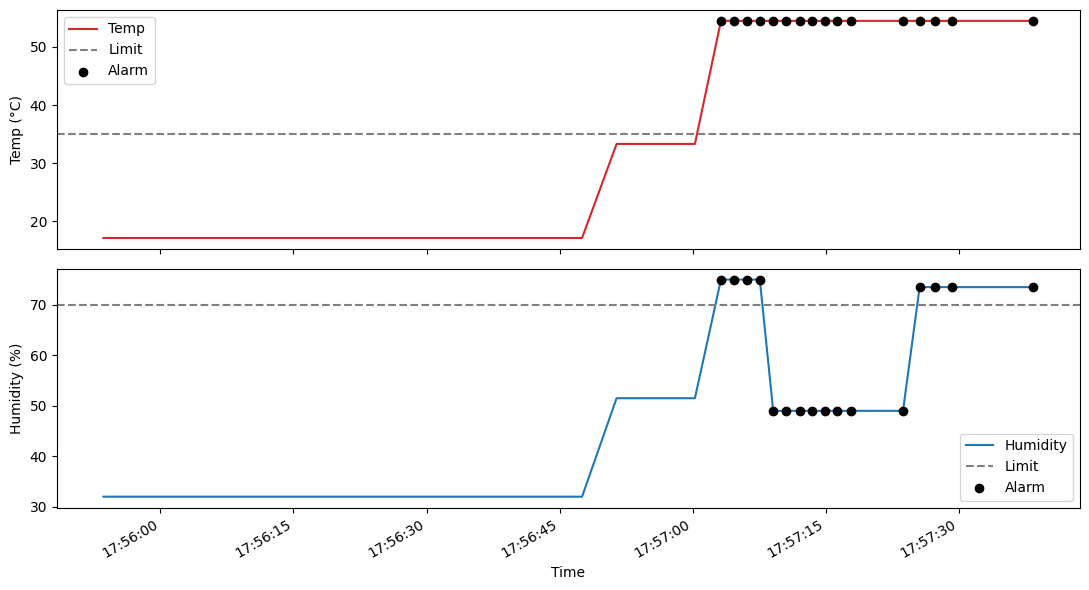

In [18]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

TEMP_LIMIT, HUM_LIMIT = 35.0, 70.0
alarms = df[df["alarm"] == 1]

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax[0].plot(df["time"], df["temp"], color="tab:red", label="Temp")
ax[0].axhline(TEMP_LIMIT, ls="--", color="gray", label="Limit")
ax[0].scatter(alarms["time"], alarms["temp"], color="black", label="Alarm", zorder=3)
ax[0].set_ylabel("Temp (°C)"); ax[0].legend()

ax[1].plot(df["time"], df["hum"], color="tab:blue", label="Humidity")
ax[1].axhline(HUM_LIMIT, ls="--", color="gray", label="Limit")
ax[1].scatter(alarms["time"], alarms["hum"], color="black", label="Alarm", zorder=3)
ax[1].set_ylabel("Humidity (%)"); ax[1].legend()

ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
fig.autofmt_xdate()

plt.xlabel("Time"); plt.tight_layout()
plt.savefig("sensor_plot.png", dpi=150)
plt.show()

In [19]:
print(df[["temp", "hum"]].describe())
print("Total readings:", len(df))
print("Alarm readings:", (df["alarm"] == 1).sum())
print("Alarm percentage: %.1f%%" % (100 * df["alarm"].mean()))

            temp        hum
count  36.000000  36.000000
mean   35.522222  47.333333
std    17.898366  16.608088
min    17.100000  32.000000
25%    17.100000  32.000000
50%    33.300000  49.000000
75%    54.500000  51.500000
max    54.500000  75.000000
Total readings: 36
Alarm readings: 16
Alarm percentage: 44.4%
